# 75 Customer segmentation with appliance flags (mixed data)

Notebook 70 clusters customers on 14 **continuous** engineered features (size, daily shape, heating and cooling
response, seasonality, grid-peak coincidence, load factor, variability, solar). This notebook adds the **appliance
inventory** from notebook 60, which is **categorical**: what kind of AC a home has, what kind of electric heating,
whether it has a water heater, pool, hot tub, EV charging or solar + battery.

### Why not just k-means?

k-means needs numbers it can average. Coding "heat pump likely" as 3 and "resistance likely" as 2 would invent an
order and a distance between categories that don't exist. One-hot encoding (a 0/1 column per category) avoids the
order, but k-means then averages the 0/1 columns into proportions and treats the distance between any two homes as
if the columns were continuous, with a weight set by an arbitrary scaling (tested at the end).

### k-prototypes

**k-prototypes** (Huang, 1998) handles both kinds of variable directly. Each cluster has a **prototype**: the
**mean** of each continuous feature (as in k-means) and the **mode**, the most common category, of each categorical
variable (as in k-modes). The distance from a customer to a prototype is

> squared distance on the standardized continuous features **+ γ × the number of categorical variables on which the
> customer differs from the prototype's mode**

and, like k-means, the algorithm alternates between assigning each customer to the nearest prototype and updating
the means and modes, until no one moves. The implementation is `avangrid.segmentation.kprototypes` (NumPy;
k-means++-style starts, the best of several random starts). **γ** sets how much one categorical mismatch counts
against the continuous features; section 2 chooses it and section 5 tests other values.

Customers with too little use for peer-relative analysis (average under 0.05 kWh/hour) aren't clustered, as in
notebook 70; they are added back as "Minimal use / vacant".

Outputs: DuckDB table `customer_segments_mixed`; `onedrive-export/Data/eda/customer_segments_mixed.csv`,
`segment_mixed_profiles.png`, `segment_mixed_k_choice.png`; result tables in `onedrive-export/Data/results/`.

Run after notebook 70. It takes a few minutes.

## Setup

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.model_selection import KFold

import avangrid  # noqa: F401
from avangrid import cache, config, db, segmentation as seg

PLOT_DIR = config.EDA_DIR

## 1. Data

**Continuous features**: notebook 70's 14 features (`segmentation.FEATURES`), standardized the same way (capped at
the 1st and 99th percentiles, centered on the median, scaled by the interquartile range, or the standard deviation
for mostly-zero features).

**Categorical features**: eight variables from `appliance_inventory` (notebook 60). Where the inventory has both a
yes/no flag and a type (AC, electric heating), the type is used, because it holds the flag too:

| Variable | Categories |
|---|---|
| `ac_type` | none detected · room / partial · central likely |
| `heating_type` | none detected · electric (type uncertain) · resistance likely · heat pump likely |
| `elec_heat_primary_flag` | no · yes (electric heating looks like the main heat source) |
| `water_heater_flag`, `pool_flag`, `hot_tub_flag` | no · yes |
| `ev_charging_type` | none detected · Level 1 likely · Level 2 likely |
| `solar_battery_flag` | no · yes |

Two of the continuous features overlap with the appliance evidence (`heat_rel` and `cool_rel` are scaled versions of
the heating and AC loads, and `solar_midday_zero_share` is also an appliance-rule input), so heating, cooling and
solar enter both parts. That is deliberate: the continuous features say *how much*, the categories *what kind*.

In [2]:
s = db.sql('SELECT * FROM customer_segments ORDER BY CUSTOMER_NUMBER')
low = s.filter(pl.col('cluster') >= 8).select('CUSTOMER_NUMBER')          # minimal-use customers (not clustered)
s = s.filter(pl.col('cluster') < 8)
inv = s.select('CUSTOMER_NUMBER').join(db.sql('SELECT * FROM appliance_inventory'), on='CUSTOMER_NUMBER', how='left')

CAT_VARS = ['ac_type', 'heating_type', 'elec_heat_primary_flag', 'water_heater_flag', 'pool_flag', 'hot_tub_flag',
            'ev_charging_type', 'solar_battery_flag']
LEVELS = {}
codes = []
for v in CAT_VARS:
    col = inv[v]
    col = pl.Series(v, np.where(col.to_numpy(), 'yes', 'no')) if col.dtype == pl.Boolean else col
    LEVELS[v] = sorted(col.unique().to_list(), key=lambda x: (x not in ('no', 'none detected'), x))  # 'none' first
    codes.append(col.replace_strict({lv: i for i, lv in enumerate(LEVELS[v])}, return_dtype=pl.Int64).to_numpy())
C = np.column_stack(codes)

X = s.select(seg.FEATURES).to_numpy().astype(float)
Z = seg.robust_standardize(X)
print(f'{len(Z):,} customers: {Z.shape[1]} continuous + {C.shape[1]} categorical variables')
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, fmt_str_lengths=40):
    print(pl.DataFrame([{'variable': v, 'category': lv, 'customers': int((C[:, j] == i).sum()),
                         'share': round(float((C[:, j] == i).mean()), 3)}
                        for j, v in enumerate(CAT_VARS) for i, lv in enumerate(LEVELS[v])]))

33,310 customers: 14 continuous + 8 categorical variables
┌────────────────────────┬───────────────────────────┬───────────┬───────┐
│ variable               ┆ category                  ┆ customers ┆ share │
│ ---                    ┆ ---                       ┆ ---       ┆ ---   │
│ str                    ┆ str                       ┆ i64       ┆ f64   │
╞════════════════════════╪═══════════════════════════╪═══════════╪═══════╡
│ ac_type                ┆ none detected             ┆ 8162      ┆ 0.245 │
│ ac_type                ┆ central likely            ┆ 12028     ┆ 0.361 │
│ ac_type                ┆ room / partial            ┆ 13120     ┆ 0.394 │
│ heating_type           ┆ none detected             ┆ 27858     ┆ 0.836 │
│ heating_type           ┆ electric (type uncertain) ┆ 3805      ┆ 0.114 │
│ heating_type           ┆ heat pump likely          ┆ 629       ┆ 0.019 │
│ heating_type           ┆ resistance likely         ┆ 1018      ┆ 0.031 │
│ elec_heat_primary_flag ┆ no             

## 2. Weighting the categorical variables (γ)

γ converts a categorical mismatch into the same units as the squared distance on the continuous features. The
common rule of thumb (Huang's) sets γ to about half the continuous features' standard deviation, which here would
give the appliances very little say: they're mostly rare, so most homes match the "none" mode anyway.

Instead γ is set so that **each variable, continuous or categorical, carries the same weight**: with all customers in
one cluster, the average squared deviation of a continuous feature (its variance) equals γ × the average mismatch
rate of a categorical variable (the share of customers not in its most common category). So

> γ = mean variance of the standardized continuous features ÷ mean mismatch rate of the categorical variables.

Section 5 shows how the clusters change at other values of γ, from 0 (k-means on the continuous features alone) up.

In [3]:
mismatch = np.array([(C[:, j] != np.bincount(C[:, j]).argmax()).mean() for j in range(C.shape[1])])
GAMMA = float(Z.var(0).mean() / mismatch.mean())
print(f'Mean variance of the continuous features: {Z.var(0).mean():.3f}')
print('Mismatch rate (share not in the most common category):',
      {v: round(float(m), 3) for v, m in zip(CAT_VARS, mismatch)})
print(f'gamma = {GAMMA:.2f}  (Huang rule of thumb, half the mean SD: {0.5 * Z.std(0).mean():.2f})')
TOTAL = seg.kproto_total_cost(Z, C, GAMMA)

Mean variance of the continuous features: 0.713
Mismatch rate (share not in the most common category): {'ac_type': 0.606, 'heating_type': 0.164, 'elec_heat_primary_flag': 0.043, 'water_heater_flag': 0.131, 'pool_flag': 0.036, 'hot_tub_flag': 0.039, 'ev_charging_type': 0.03, 'solar_battery_flag': 0.001}
gamma = 5.44  (Huang rule of thumb, half the mean SD: 0.42)


## 3. Choosing the number of clusters

For k = 4–12, three measures, as in notebook 70:

- **Share of cost explained**: 1 − total distance of customers to their prototype ÷ the same with one cluster. The
  k-prototypes version of variance accounted for; it rises with k.
- **Held-out share explained (5-fold)**: prototypes fitted on four folds, the fifth fold's customers assigned to the
  nearest one and their cost compared with their own one-cluster cost. If it tracks the training figure, the
  clusters describe the population rather than the customers they were fitted on.
- **Stability across random starts**: adjusted Rand index between the clusterings from three different seeds (1 =
  identical). Mixed-data clusterings with a weak k can flip between quite different solutions.

This cell takes a few minutes.

┌─────┬───────────┬────────────────────┬─────────────────────┬───────────────┬─────────────────────┐
│ k   ┆ explained ┆ explained_held_out ┆ categorical_share_o ┆ stability_ari ┆ smallest_cluster_sh │
│ --- ┆ ---       ┆ ---                ┆ f_cost              ┆ ---           ┆ are                 │
│ i64 ┆ f64       ┆ f64                ┆ ---                 ┆ f64           ┆ ---                 │
│     ┆           ┆                    ┆ f64                 ┆               ┆ f64                 │
╞═════╪═══════════╪════════════════════╪═════════════════════╪═══════════════╪═════════════════════╡
│ 4   ┆ 0.354     ┆ 0.349              ┆ 0.274               ┆ 0.999         ┆ 0.054               │
│ 5   ┆ 0.404     ┆ 0.395              ┆ 0.262               ┆ 0.790         ┆ 0.050               │
│ 6   ┆ 0.437     ┆ 0.430              ┆ 0.236               ┆ 0.876         ┆ 0.039               │
│ 7   ┆ 0.453     ┆ 0.450              ┆ 0.268               ┆ 0.526         ┆ 0.037       

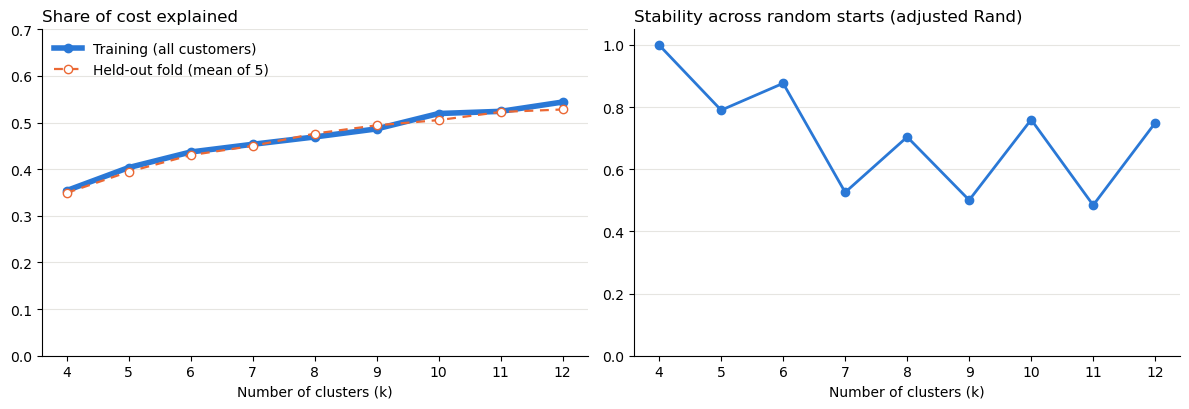

In [4]:
KS = range(4, 13)
rows = []
folds = list(KFold(5, shuffle=True, random_state=0).split(Z))
for k in KS:
    fits = [seg.kprototypes(Z, C, k, GAMMA, n_init=5, seed=sd) for sd in range(3)]
    stab = np.mean([adjusted_rand_score(fits[0]['labels'], fits[i]['labels']) for i in (1, 2)])
    held = []
    for tr, te in folds:
        f = seg.kprototypes(Z[tr], C[tr], k, GAMMA, n_init=3, seed=0)
        D = seg.kproto_distances(Z[te], C[te], f['centers'], f['modes'], GAMMA)
        held.append(1 - D.min(1).sum() / seg.kproto_total_cost(Z[te], C[te], GAMMA))
    rows.append({'k': k, 'explained': 1 - fits[0]['cost'] / TOTAL, 'explained_held_out': float(np.mean(held)),
                 'categorical_share_of_cost': fits[0]['cat_cost'] / fits[0]['cost'], 'stability_ari': float(stab),
                 'smallest_cluster_share': float(np.bincount(fits[0]['labels']).min() / len(Z))})
k_choice = pl.DataFrame(rows)
cache.save_results('segmentation_mixed_k_choice', k_choice)
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=3):
    print(k_choice)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
a1.plot(k_choice['k'], k_choice['explained'], color='#2a78d6', linewidth=4, marker='o', label='Training (all customers)')
a1.plot(k_choice['k'], k_choice['explained_held_out'], color='#eb6834', linewidth=1.6, linestyle=(0, (4, 3)),
        marker='o', markerfacecolor='white', label='Held-out fold (mean of 5)')
a1.set_ylim(0, 0.7)
a1.set_title('Share of cost explained', loc='left')
a1.legend(frameon=False, loc='upper left')
a2.plot(k_choice['k'], k_choice['stability_ari'], color='#2a78d6', linewidth=2, marker='o')
a2.set_ylim(0, 1.05)
a2.set_title('Stability across random starts (adjusted Rand)', loc='left')
for ax in (a1, a2):
    ax.set_xlabel('Number of clusters (k)')
    ax.set_xticks(list(KS))
    ax.grid(axis='y', color='#e6e5e1')
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'segment_mixed_k_choice.png', dpi=150)
plt.show()

## 4. Final clustering (k = 6)

k = 6 is chosen from section 3 (see the conclusions at the end for why). The final fit takes the best of 20 random
starts. Clusters are renumbered from largest to smallest, so the numbering doesn't depend on the random starts.

In [5]:
K_MIXED = 6
fit = seg.kprototypes(Z, C, K_MIXED, GAMMA, n_init=20, seed=0)
order = np.argsort(-np.bincount(fit['labels'], minlength=K_MIXED))
relabel = np.empty(K_MIXED, int)
relabel[order] = np.arange(K_MIXED)
labels = relabel[fit['labels']]
centers, modes = fit['centers'][order], fit['modes'][order]
print(f"cost explained {1 - fit['cost'] / TOTAL:.3f}; categorical share of the within-cluster cost "
      f"{fit['cat_cost'] / fit['cost']:.3f}; {fit['n_iter']} iterations")
print('customers per cluster:', dict(enumerate(np.bincount(labels).tolist())))

cost explained 0.437; categorical share of the within-cluster cost 0.237; 24 iterations
customers per cluster: {0: 11189, 1: 10250, 2: 5483, 3: 3590, 4: 1519, 5: 1279}


## 5. How much does γ matter?

The same k, refitted with γ from 0 (the categories are ignored: k-means on the continuous features) to four times the
chosen value. For each: agreement with the chosen clustering and with notebook 70's clusters (adjusted Rand), the
categorical share of the within-cluster cost, and **appliance purity**: the share of customers who match their
cluster's mode on each categorical variable, averaged over the variables that aren't "none" for most customers
(AC type, heating type, water heater).

In [6]:
PURITY_VARS = [CAT_VARS.index(v) for v in ['ac_type', 'heating_type', 'water_heater_flag']]


def purity(lab, md):
    return float(np.mean([(C[:, j] == md[lab, j]).mean() for j in PURITY_VARS]))


sens = []
for mult in [0, 0.25, 0.5, 1, 2, 4]:
    f = seg.kprototypes(Z, C, K_MIXED, GAMMA * mult, n_init=10, seed=0)
    sens.append({'gamma_multiple': mult, 'gamma': GAMMA * mult,
                 'ari_vs_chosen': adjusted_rand_score(labels, f['labels']),
                 'ari_vs_notebook_70': adjusted_rand_score(s['cluster'], f['labels']),
                 'categorical_share_of_cost': f['cat_cost'] / f['cost'] if mult else 0.0,
                 'appliance_purity': purity(f['labels'], f['modes'])})
sens = pl.DataFrame(sens)
cache.save_results('segmentation_mixed_gamma', sens)
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=3):
    print(sens)

┌────────────────┬────────┬───────────────┬──────────────────┬──────────────────┬──────────────────┐
│ gamma_multiple ┆ gamma  ┆ ari_vs_chosen ┆ ari_vs_notebook_ ┆ categorical_shar ┆ appliance_purity │
│ ---            ┆ ---    ┆ ---           ┆ 70               ┆ e_of_cost        ┆ ---              │
│ f64            ┆ f64    ┆ f64           ┆ ---              ┆ ---              ┆ f64              │
│                ┆        ┆               ┆ f64              ┆ f64              ┆                  │
╞════════════════╪════════╪═══════════════╪══════════════════╪══════════════════╪══════════════════╡
│ 0.000          ┆ 0.000  ┆ 0.149         ┆ 0.482            ┆ 0.000            ┆ 0.747            │
│ 0.250          ┆ 1.359  ┆ 0.243         ┆ 0.506            ┆ 0.155            ┆ 0.795            │
│ 0.500          ┆ 2.719  ┆ 0.668         ┆ 0.222            ┆ 0.179            ┆ 0.883            │
│ 1.000          ┆ 5.438  ┆ 0.945         ┆ 0.129            ┆ 0.236            ┆ 0.911    

## 6. What each cluster looks like

For each cluster: its share of customers, of annual energy and of use in the grid's 100 highest hours; median size;
the share of homes with each appliance; and the median of each standardized continuous feature (0 = a typical
customer, ±1 ≈ one interquartile range away). Each cluster gets an automatic **description** listing its most
distinctive traits: continuous features whose median is at least 0.6 away from 0, and appliance categories at least
1.5 times as common as overall that cover at least 40% of the cluster.

In [7]:
CAT_LABELS = {('ac_type', 'central likely'): 'central AC', ('ac_type', 'room / partial'): 'room AC',
              ('heating_type', 'heat pump likely'): 'heat pump', ('heating_type', 'resistance likely'): 'resistance heat',
              ('heating_type', 'electric (type uncertain)'): 'electric heat (type uncertain)',
              ('elec_heat_primary_flag', 'yes'): 'primary electric heat', ('water_heater_flag', 'yes'): 'water heater',
              ('pool_flag', 'yes'): 'pool', ('hot_tub_flag', 'yes'): 'hot tub', ('ev_charging_type', 'Level 1 likely'): 'EV Level 1',
              ('ev_charging_type', 'Level 2 likely'): 'EV Level 2', ('solar_battery_flag', 'yes'): 'solar + battery'}
WORDS = {'log_mean_kwh': ('large', 'small'), 'night_share': ('overnight use', 'little overnight use'),
         'morning_share': ('morning-heavy', 'light mornings'), 'afternoon_share': ('daytime use', 'empty daytime'),
         'evening_share': ('evening-heavy', 'light evenings'), 'evening_peak_ratio': ('evening peak', 'flat evenings'),
         'heat_rel': ('strong heating response', 'little heating'), 'cool_rel': ('heavy cooling', 'little cooling'),
         'log_winter_summer': ('winter-peaking', 'summer-peaking'), 'empty_months': ('part-year vacant', 'occupied all year'),
         'grid_peak_ratio': ('peak-coincident', 'off-peak'), 'load_factor': ('steady', 'peaky'),
         'daily_cv': ('variable day to day', 'regular'), 'solar_midday_zero_share': ('solar', 'no solar')}
prev = {lab: np.array([(C[labels == j, CAT_VARS.index(v)] == LEVELS[v].index(lv)).mean() for j in range(K_MIXED)])
        for (v, lv), lab in CAT_LABELS.items()}
overall = {lab: float((C[:, CAT_VARS.index(v)] == LEVELS[v].index(lv)).mean()) for (v, lv), lab in CAT_LABELS.items()}
zmed = np.vstack([np.median(Z[labels == j], 0) for j in range(K_MIXED)])


def describe(j):
    num = [(abs(zmed[j, i]), WORDS[f][0 if zmed[j, i] > 0 else 1]) for i, f in enumerate(seg.FEATURES) if abs(zmed[j, i]) >= 0.6]
    cat = [(prev[lab][j] / max(overall[lab], 1e-9), f'{lab} {prev[lab][j]:.0%}') for lab in prev
           if prev[lab][j] >= 0.4 and prev[lab][j] >= 1.5 * overall[lab]]
    traits = [t for _, t in sorted(cat, reverse=True)[:3]] + [t for _, t in sorted(num, reverse=True)[:3]]
    return ', '.join(traits) if traits else 'typical on every measure'


energy = np.exp(s['log_mean_kwh'].to_numpy())
peak = s['grid_peak_kwh'].to_numpy()
profile = pl.DataFrame({
    'cluster': np.arange(K_MIXED),
    'description': [describe(j) for j in range(K_MIXED)],
    'customers': np.bincount(labels),
    'share_customers': np.bincount(labels) / len(labels),
    'share_energy': np.bincount(labels, energy) / energy.sum(),
    'share_grid_peak': np.bincount(labels, peak) / peak.sum(),
    'median_kw': [float(np.median(energy[labels == j])) for j in range(K_MIXED)],
    **{lab: prev[lab] for lab in prev},
})
cache.save_results('segment_mixed_summary', profile)
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=250, tbl_hide_dataframe_shape=True, float_precision=2,
               fmt_str_lengths=110):
    print(profile.select('cluster', 'description', 'customers', 'share_customers', 'share_energy', 'share_grid_peak',
                         'median_kw'))
    print(profile.select('cluster', *prev.keys()))

┌─────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────┬───────────┬─────────────────┬──────────────┬─────────────────┬───────────┐
│ cluster ┆ description                                                                                                  ┆ customers ┆ share_customers ┆ share_energy ┆ share_grid_peak ┆ median_kw │
│ ---     ┆ ---                                                                                                          ┆ ---       ┆ ---             ┆ ---          ┆ ---             ┆ ---       │
│ i64     ┆ str                                                                                                          ┆ i64       ┆ f64             ┆ f64          ┆ f64             ┆ f64       │
╞═════════╪══════════════════════════════════════════════════════════════════════════════════════════════════════════════╪═══════════╪═════════════════╪══════════════╪═════════════════╪═══════════╡
│ 0       

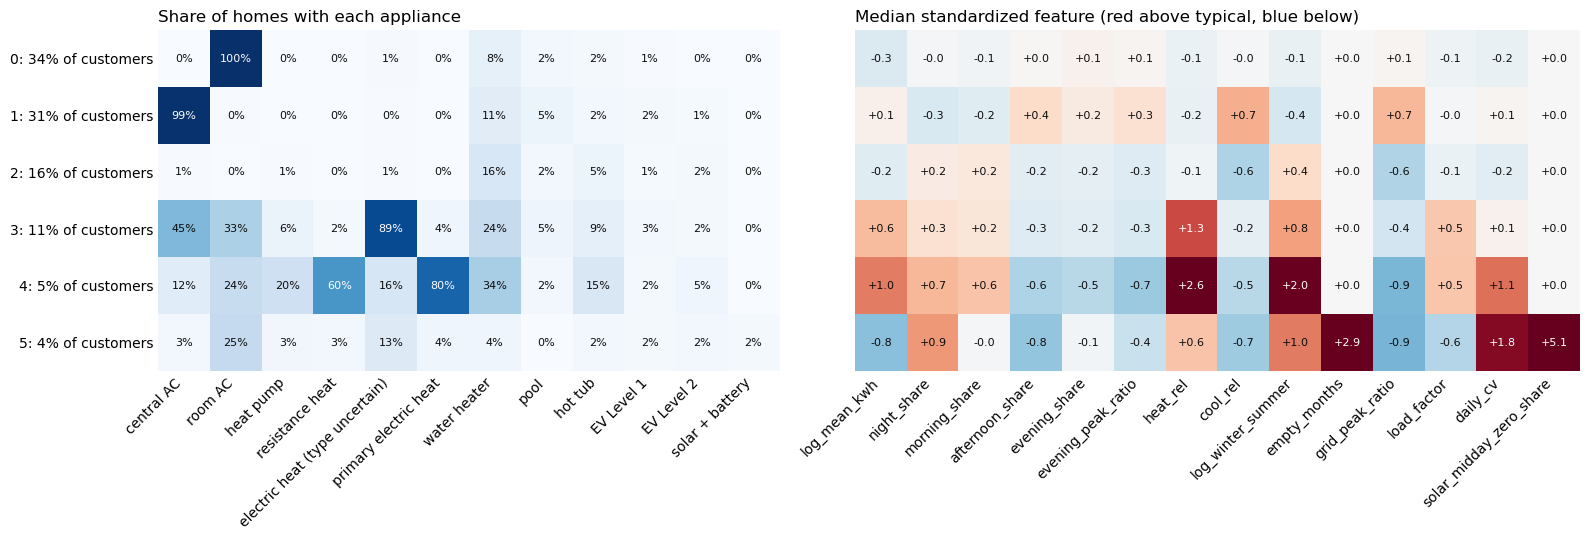

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 0.55 * K_MIXED + 2.2), gridspec_kw={'width_ratios': [12, 14]})
P = np.column_stack([prev[lab] for lab in prev])
a1.imshow(P, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for (i, j), v in np.ndenumerate(P):
    a1.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8, color='white' if v > 0.55 else '#0b0b0b')
a1.set_xticks(range(len(prev)), list(prev), rotation=45, ha='right')
a1.set_title('Share of homes with each appliance', loc='left')
a2.imshow(zmed, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
for (i, j), v in np.ndenumerate(zmed):
    a2.text(j, i, f'{v:+.1f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 1.3 else '#0b0b0b')
a2.set_xticks(range(len(seg.FEATURES)), seg.FEATURES, rotation=45, ha='right')
a2.set_title('Median standardized feature (red above typical, blue below)', loc='left')
ylab = [f"{j}: {profile['share_customers'][j]:.0%} of customers" for j in range(K_MIXED)]
a1.set_yticks(range(K_MIXED), ylab)
a2.set_yticks(range(K_MIXED), [''] * K_MIXED)
for ax in (a1, a2):
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(PLOT_DIR / 'segment_mixed_profiles.png', dpi=150)
plt.show()

## 7. Compared with notebook 70's clusters

Rows: notebook 70's behavioural segments; columns: the clusters here. Each cell is the number of customers in both.

In [9]:
print(f"Adjusted Rand index with notebook 70's clusters: {adjusted_rand_score(s['cluster'], labels):.2f}")
xt = (pl.DataFrame({'notebook_70_segment': s['segment'], 'cluster': labels})
      .group_by('notebook_70_segment', 'cluster').len()
      .pivot(on='cluster', index='notebook_70_segment', values='len', sort_columns=True).fill_null(0)
      .sort('notebook_70_segment'))
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200, tbl_hide_dataframe_shape=True, fmt_str_lengths=40):
    print(xt)

Adjusted Rand index with notebook 70's clusters: 0.13
┌─────────────────────────────────┬──────┬──────┬──────┬──────┬──────┬─────┐
│ notebook_70_segment             ┆ 0    ┆ 1    ┆ 2    ┆ 3    ┆ 4    ┆ 5   │
│ ---                             ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ ---  ┆ --- │
│ str                             ┆ u32  ┆ u32  ┆ u32  ┆ u32  ┆ u32  ┆ u32 │
╞═════════════════════════════════╪══════╪══════╪══════╪══════╪══════╪═════╡
│ Daytime-active, AC              ┆ 2399 ┆ 1319 ┆ 1212 ┆ 237  ┆ 1    ┆ 3   │
│ Electric-heated, winter-peaking ┆ 219  ┆ 10   ┆ 415  ┆ 1789 ┆ 1186 ┆ 19  │
│ Evening peakers                 ┆ 2794 ┆ 2519 ┆ 735  ┆ 196  ┆ 1    ┆ 4   │
│ Large, steady homes             ┆ 2386 ┆ 2193 ┆ 1216 ┆ 1253 ┆ 27   ┆ 0   │
│ Seasonal / part-year vacant     ┆ 57   ┆ 38   ┆ 48   ┆ 7    ┆ 300  ┆ 694 │
│ Small, flat, low-AC             ┆ 2208 ┆ 338  ┆ 1798 ┆ 77   ┆ 0    ┆ 11  │
│ Solar homes                     ┆ 16   ┆ 4    ┆ 24   ┆ 6    ┆ 4    ┆ 531 │
│ Summer peakers (heav

## 8. Alternative: one-hot encoding + k-means

The usual workaround: one 0/1 column per category, appended to the continuous features, then ordinary k-means. Each
0/1 column is scaled by √(γ/2), so that disagreeing on one categorical variable (two columns differ by the scale)
costs γ, the same as in k-prototypes. The difference is in the centers: k-means averages the 0/1 columns into
proportions, so a cluster center is "40% pool" rather than "no pool", and a customer's distance to it depends on
how mixed the cluster is.

In [10]:
onehot = np.column_stack([(C[:, j] == i).astype(float) for j, v in enumerate(CAT_VARS) for i in range(len(LEVELS[v]))])
km = KMeans(K_MIXED, n_init=20, random_state=0).fit_predict(np.hstack([Z, onehot * np.sqrt(GAMMA / 2)]))
km_modes = np.vstack([[np.bincount(C[km == j, v], minlength=len(LEVELS[CAT_VARS[v]])).argmax() for v in range(C.shape[1])]
                      for j in range(K_MIXED)])
print(f'Agreement with k-prototypes (adjusted Rand): {adjusted_rand_score(labels, km):.2f}')
print(f"Agreement with notebook 70: {adjusted_rand_score(s['cluster'], km):.2f}")
print(f'Appliance purity: k-prototypes {purity(labels, modes):.3f}, one-hot k-means {purity(km, km_modes):.3f}')
print('Cluster sizes, one-hot k-means:', sorted(np.bincount(km).tolist(), reverse=True))

Agreement with k-prototypes (adjusted Rand): 0.74
Agreement with notebook 70: 0.21
Appliance purity: k-prototypes 0.912, one-hot k-means 0.891
Cluster sizes, one-hot k-means: [10677, 6376, 5570, 5404, 3974, 1309]


## 9. Save

`customer_segments_mixed` (one row per customer in `customer_segments`): the cluster and its description, with
notebook 70's cluster and segment alongside for comparison. Minimal-use customers get cluster K and the description
"Minimal use / vacant", as in notebook 70.

In [11]:
desc = profile['description'].to_list()
out = pl.concat([
    s.select('CUSTOMER_NUMBER', pl.col('cluster').alias('notebook_70_cluster'), pl.col('segment').alias('notebook_70_segment'))
     .with_columns(pl.Series('mixed_cluster', labels, dtype=pl.Int64), pl.Series('mixed_description', [desc[j] for j in labels])),
    low.join(db.sql('SELECT CUSTOMER_NUMBER, cluster AS notebook_70_cluster, segment AS notebook_70_segment '
                    'FROM customer_segments'), on='CUSTOMER_NUMBER')
       .with_columns(pl.lit(K_MIXED, dtype=pl.Int64).alias('mixed_cluster'), pl.lit('Minimal use / vacant').alias('mixed_description')),
], how='diagonal').sort('CUSTOMER_NUMBER')
with db.connect(read_only=False) as con:
    con.register('mixed_df', out)
    con.execute('CREATE OR REPLACE TABLE customer_segments_mixed AS SELECT * FROM mixed_df ORDER BY CUSTOMER_NUMBER')
out.write_csv(PLOT_DIR / 'customer_segments_mixed.csv')
cache.save_results('customer_segments_mixed', out)
print(f'customer_segments_mixed: {out.height:,} customers in {out["mixed_cluster"].n_unique()} groups')

customer_segments_mixed: 33,566 customers in 7 groups


## What the clusters show

*Figures from the 13 Nov 2026 run (33,310 customers); the tables above update on a re-run, this text doesn't.*

**Choice of k = 6.** k = 6 is the best balance of stability across random starts (adjusted Rand 0.88), interpretability
and cluster size (the smallest holds 4% of customers). k = 4 is even more stable but merges groups that matter
(the two kinds of electric heating). k = 5 and 7–12 are less stable (adjusted Rand 0.48–0.79): mixed-data
solutions with too many clusters flip between quite different answers from one random start to the next. Held-out
customers fit the prototypes as well as the customers they were fitted on (cost explained 0.430 vs 0.437), so the
clusters aren't overfitted.

| Cluster | Share of customers | Share of energy | Share of grid-peak use | What defines it |
|---|---|---|---|---|
| 0 Room-AC homes | 34% | 25% | 26% | All room or partial AC; otherwise typical |
| 1 Central-AC, peak-coincident | 31% | 32% | **47%** | Central AC (99%), heavy cooling, use concentrated in the grid's peak hours |
| 2 No AC detected | 16% | 14% | 9% | Little cooling, little use in peak hours |
| 3 Large, electric heat (type uncertain) | 11% | 17% | 14% | Electric heating (89%) with central or room AC, strong heating response, winter-peaking, large (median 1.35 kW) |
| 4 Primary electric heat | 5% | 10% | 4% | Electric heat as the main source (80%), mostly resistance (60%) or heat pump (20%); the largest homes (median 1.89 kW), winter-peaking |
| 5 Solar and part-year homes | 4% | 2% | 1% | Solar-like midday zeros, months nearly empty, variable |

**What adding the appliances changes.** The clusters differ substantially from notebook 70's (adjusted Rand 0.13).
Notebook 70 separates homes mainly by *when* they use electricity (evening peakers, daytime-active, summer peakers);
here **AC type** organises most of the population, because it's the categorical variable with the most variety (three
common categories). That split is useful: the central-AC cluster holds 31% of customers but 47% of use in the 100
highest grid hours, which makes it the clearest demand-response and battery target. Electric heating splits into two
groups with different programme fits: cluster 4 (primary electric heat, mostly resistance) holds half of the likely
heat-pump homes and is the natural heat-pump retrofit and winter-peak group.

**What it doesn't do.** Rare appliances (EV charging, 1–2% of homes; pool and hot tub, about 4%; solar + battery,
0.1%) never become a cluster's mode at this k, because a prototype holds each variable's *most common* category. They
nudge assignments (pool homes concentrate in the central-AC cluster: 559 of 1,187), but to target them, use the
inventory flags or notebook 70's program segments (`flexible_load`, `high_electrification`) directly.

**How robust it is to γ.** With γ at half the chosen value or less, the clusters drift back towards notebook 70's
(adjusted Rand 0.48–0.51 at γ = 0 and 0.25×). From half the chosen value upwards they are appliance-led, and at 1–4×
they agree closely with the chosen clustering (adjusted Rand 0.82–0.95). So once the appliances have a fair say,
the exact weight doesn't change the picture much.

## Tried but not used

| Tried | Why it isn't used |
|---|---|
| **A smaller categorical weight**: Huang's rule of thumb (half the continuous features' mean standard deviation, about 0.4) or one variance (about 0.7) | The appliances then account for only about a tenth of the within-cluster cost, and the clusters mostly reproduce notebook 70's (section 5, low-γ rows). That would defeat the purpose of adding them. |
| **Other numbers of clusters** (k = 4–12) | k = 5 and 7–12 are unstable across random starts (adjusted Rand 0.48–0.79). k = 4 is stable but merges the two kinds of electric heating. |
| **One-hot encoding + k-means** (section 8) | Agrees moderately with k-prototypes (adjusted Rand 0.74) but gives less pure clusters (0.891 vs 0.912), and its centers are mixtures ("40% pool") rather than a profile you can name. |
| **Gower distance with k-medoids or hierarchical clustering**, the other standard method for mixed data | Considered, not run. It needs every pairwise distance: 33,310² ≈ 1.1 billion pairs, about 9 GB, so it would only work on a sample. |
| **The plain AC and electric-heating yes/no flags** alongside their type variables | Left out: the type already contains the flag, so including both would count the same information twice. |
| **A mixed-data clustering package** (`kmodes`) | Not installed in this environment; k-prototypes is short enough to implement directly (`avangrid.segmentation.kprototypes`), which also keeps it inspectable. |